<a href="https://colab.research.google.com/github/GUNJANSUMAN/accomadationfeedback/blob/main/assgn_dnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Section 1.1 - Install Required Libraries

%pip install torch numpy pandas matplotlib scikit-learn tqdm


In [2]:

# Section 1.2 - Import Required Libraries

# Basic Python libraries
import os
import random
import time
from pathlib import Path

# Data handling and numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Deep learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Evaluation metrics
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# Training progress
from tqdm.auto import tqdm

print("All required libraries imported successfully.")


All required libraries imported successfully.


In [3]:
# Section 1.3 - Check GPU and Device

import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU is available.")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU is not available. Using CPU.")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

GPU is available.
GPU: Tesla T4
PyTorch version: 2.14.1+cu130
Selected device: cuda


In [4]:

# Section 1.4 - Assignment Configuration

# Student information
STUDENT_ID = "05160"

# Individual experiment based on the last digit of the student ID
# Even ID: RNN gradient clipping experiment
INDIVIDUAL_ABLATION = "RNN Gradient Clipping"


# Random seeds for reproducible experiments
# These are working seeds; replace them if the instructor's
# individualisation table specifies different values.
SEEDS = [42, 123, 2026]


# UCI HAR dataset parameters
INPUT_SIZE = 9
SEQUENCE_LENGTH = 128
NUM_CLASSES = 6

CLASS_NAMES = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]


# Recurrent neural network parameters
# Hidden size 64 is provisional for HAR until the
# assigned value in the individualisation table is confirmed.
HIDDEN_SIZE = 64

LEARNING_RATE = 0.001
BATCH_SIZE = 128
EPOCHS = 20


# Adding problem parameters
SEQUENCE_LENGTHS = [50, 100, 200, 400]

TRAIN_SAMPLES = 10000
VALIDATION_SAMPLES = 1000
TEST_SAMPLES = 1000

MSE_BASELINE = 0.167
SOLVED_THRESHOLD = 0.05


print("Assignment configuration defined successfully.")


Assignment configuration defined successfully.


In [5]:

# Section 1.5 - Random Seed Initialization

def set_seed(seed):
    # Set seed for Python random operations
    random.seed(seed)

    # Set seed for NumPy operations
    np.random.seed(seed)

    # Set seed for PyTorch CPU operations
    torch.manual_seed(seed)

    # Set seed for PyTorch GPU operations
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Initialize the notebook with the first experiment seed
set_seed(SEEDS[0])

print("Random seed initialized successfully:", SEEDS[0])


Random seed initialized successfully: 42


In [6]:
from pathlib import Path

# Section 1.6 - Create Project Directories

# Set the current working directory as the project root
PROJECT_DIR = Path.cwd()

# Define directories for datasets and Problem 1 outputs
DATA_DIR = PROJECT_DIR / "data"
HAR_DATA_DIR = DATA_DIR / "UCI_HAR"

PROBLEM1_DIR = PROJECT_DIR / "problem1"
FIGURES_DIR = PROBLEM1_DIR / "figures"

# Create the required directories
for folder in [DATA_DIR, HAR_DATA_DIR, PROBLEM1_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directories created successfully.")

Project directories created successfully.


In [7]:
import pandas as pd
from pathlib import Path

# Section 1.7 - Initialize Experiment Results

# Define the current working directory
PROJECT_DIR = Path.cwd()

# Define the columns required by the assignment
RESULT_COLUMNS = [
    "problem",
    "model",
    "seed",
    "seq_len",
    "test_acc",
    "macro_f1",
    "test_mse",
    "params",
    "sec_per_epoch",
    "val_loss_nats",
    "bits_per_char",
    "notes"
]

# Set the results file location
RESULTS_FILE = PROJECT_DIR / "results.csv"

# Create an empty results file if it does not already exist
if not RESULTS_FILE.exists():
    pd.DataFrame(columns=RESULT_COLUMNS).to_csv(
        RESULTS_FILE, index=False
    )

print("Results file initialized:", RESULTS_FILE)

Results file initialized: /content/results.csv


In [8]:

# Section 1.8 - Configuration Summary

print("DNN PROGRAMMING ASSIGNMENT")
print("-" * 40)

print("Student ID       :", STUDENT_ID)
print("Computing Device :", device)
print("Random Seeds     :", SEEDS)

print("\nHAR Configuration")
print("Input Channels   :", INPUT_SIZE)
print("Sequence Length  :", SEQUENCE_LENGTH)
print("Number of Classes:", NUM_CLASSES)
print("Hidden Size      :", HIDDEN_SIZE)

print("\nAdding Problem")
print("Sequence Lengths :", SEQUENCE_LENGTHS)

print("\nIndividual Ablation")
print("Experiment       :", INDIVIDUAL_ABLATION)

print("\nResults File     :", RESULTS_FILE)

print("\nMODULE 1 COMPLETED")


DNN PROGRAMMING ASSIGNMENT
----------------------------------------
Student ID       : 05160
Computing Device : cuda
Random Seeds     : [42, 123, 2026]

HAR Configuration
Input Channels   : 9
Sequence Length  : 128
Number of Classes: 6
Hidden Size      : 64

Adding Problem
Sequence Lengths : [50, 100, 200, 400]

Individual Ablation
Experiment       : RNN Gradient Clipping

Results File     : /content/results.csv

MODULE 1 COMPLETED


In [9]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Section 2.1 - Download and Extract UCI HAR Dataset

# Define project and data directories
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
DOWNLOAD_DIR = DATA_DIR / "har"
HAR_ARCHIVE = DATA_DIR / "har.zip"

# Recreate data directories
DATA_DIR.mkdir(parents=True, exist_ok=True)
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Official UCI HAR dataset download link
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

# Download the dataset
print("Downloading dataset...")
urllib.request.urlretrieve(HAR_URL, HAR_ARCHIVE)
print("Download completed.")

# Extract the outer zip archive
print("Extracting main archive...")
with zipfile.ZipFile(HAR_ARCHIVE, "r") as zip_file:
    zip_file.extractall(DOWNLOAD_DIR)

# Extract the nested dataset zip archive
INNER_ARCHIVE = DOWNLOAD_DIR / "UCI HAR Dataset.zip"
if INNER_ARCHIVE.exists():
    print("Extracting nested dataset archive...")
    with zipfile.ZipFile(INNER_ARCHIVE, "r") as zip_file:
        zip_file.extractall(DOWNLOAD_DIR)

# Set the verified dataset directory path
HAR_DATA_DIR = DOWNLOAD_DIR / "UCI HAR Dataset"

# Double check existence
if HAR_DATA_DIR.exists():
    print("UCI HAR dataset successfully downloaded and verified!")
    print("Dataset path:", HAR_DATA_DIR)
else:
    print("Extraction might have failed. Current contents of har folder:")
    print(os.listdir(DOWNLOAD_DIR))

Download completed.
Extracting main archive...
Extracting nested dataset archive...
UCI HAR dataset successfully downloaded and verified!
Dataset path: /content/data/har/UCI HAR Dataset


In [10]:
from pathlib import Path
import numpy as np
import os

# Section 2.2 - Load UCI HAR Sensor Data

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"

# Debug: Print the contents of DATA_DIR to find where files were extracted
print("=== Debugging Directory Structure ===")
if DATA_DIR.exists():
    print(f"Contents of {DATA_DIR}:")
    for root, dirs, files in os.walk(DATA_DIR):
        # limit depth to keep printout concise
        depth = root.replace(str(DATA_DIR), '').count(os.sep)
        if depth < 3:
            print("  " * depth + f"- {os.path.basename(root)}/ ({len(dirs)} dirs, {len(files)} files)")
else:
    print(f"{DATA_DIR} does not exist!")
print("=====================================\n")

# Dynamically locate the true dataset root directory containing the 'train' folder
candidates = list(DATA_DIR.rglob("train"))
if candidates:
    # The parent of the 'train' folder is the correct dataset directory
    HAR_DATA_DIR = candidates[0].parent
else:
    # If not found via rglob, fallback to standard path
    HAR_DATA_DIR = DATA_DIR / "har" / "UCI HAR Dataset"

# Sensor channels in the order specified by the assignment
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

# Function to load the nine sensor channels
def load_sensor_data(split):
    signal_dir = HAR_DATA_DIR / split / "Inertial Signals"

    if not signal_dir.exists():
        raise FileNotFoundError(f"Signal directory not found: {signal_dir}")

    signals = [
        np.loadtxt(signal_dir / f"{channel}_{split}.txt")
        for channel in CHANNELS
    ]

    # Combine channels into (samples, time steps, channels)
    return np.stack(signals, axis=-1).astype(np.float32)

try:
    # Load training and testing sensor data
    X_train_raw = load_sensor_data("train")
    X_test_raw = load_sensor_data("test")

    # Load activity labels and convert them from 1-6 to 0-5
    y_train = np.loadtxt(
        HAR_DATA_DIR / "train" / "y_train.txt"
    ).astype(np.int64) - 1

    y_test = np.loadtxt(
        HAR_DATA_DIR / "test" / "y_test.txt"
    ).astype(np.int64) - 1

    # Load subject IDs
    subject_train = np.loadtxt(
        HAR_DATA_DIR / "train" / "subject_train.txt"
    ).astype(np.int64)

    subject_test = np.loadtxt(
        HAR_DATA_DIR / "test" / "subject_test.txt"
    ).astype(np.int64)

    # Display dataset dimensions
    print("Dataset path successfully resolved to:", HAR_DATA_DIR)
    print("Training data shape:", X_train_raw.shape)
    print("Testing data shape :", X_test_raw.shape)
    print("Training labels    :", y_train.shape)
    print("Testing labels     :", y_test.shape)
except Exception as e:
    print(f"Error loading data from path: {HAR_DATA_DIR}")
    print("Error details:", str(e))

=== Debugging Directory Structure ===
Contents of /content/data:
- data/ (2 dirs, 1 files)
  - UCI_HAR/ (0 dirs, 0 files)
  - har/ (2 dirs, 2 files)
    - __MACOSX/ (1 dirs, 1 files)
    - UCI HAR Dataset/ (2 dirs, 5 files)

Dataset path successfully resolved to: /content/data/har/UCI HAR Dataset
Training data shape: (7352, 128, 9)
Testing data shape : (2947, 128, 9)
Training labels    : (7352,)
Testing labels     : (2947,)


In [11]:

# Section 2.3 - Subject-wise Validation Split

def create_subject_split(seed):

    # Identify unique subjects in the training dataset
    train_subjects = np.unique(subject_train)

    # Randomly select four subjects for validation
    validation_subjects = np.random.default_rng(seed).choice(
        train_subjects, size=4, replace=False
    )

    # Separate training and validation observations
    validation_mask = np.isin(subject_train, validation_subjects)
    training_mask = ~validation_mask

    return training_mask, validation_mask, validation_subjects


# Generate the first subject-wise split
train_mask, val_mask, validation_subjects = create_subject_split(SEEDS[0])

print("Validation subjects:", sorted(validation_subjects))
print("Training samples:", np.sum(train_mask))
print("Validation samples:", np.sum(val_mask))


Validation subjects: [np.int64(3), np.int64(16), np.int64(22), np.int64(23)]
Training samples: 5952
Validation samples: 1400


In [14]:

# Section 2.5(a) - Define HAR Dataset

class HARDSataset(Dataset):

    def __init__(self, features, labels):

        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, index):

        return self.features[index], self.labels[index]


In [17]:
def prepare_har_data(seed):
    # Create a subject-wise split for validation
    train_mask, val_mask, _ = create_subject_split(seed)

    # Split raw training and label data into training and validation sets
    # We access the global arrays safely without reassigning the global variable names
    X_tr = X_train_raw[train_mask]
    y_tr = y_train[train_mask]

    X_val = X_train_raw[val_mask]
    y_v = y_train[val_mask]

    return {
        "X_train": X_tr,
        "y_train": y_tr,
        "X_val": X_val,
        "y_val": y_v,
        "X_test": X_test_raw,
        "y_test": y_test
    }

# Section 2.5(b) - Create DataLoaders

def create_har_loaders(seed):

    # Prepare data for the selected random seed
    data = prepare_har_data(seed)

    # Create dataset objects
    train_dataset = HARDSataset(data["X_train"], data["y_train"])
    val_dataset = HARDSataset(data["X_val"], data["y_val"])
    test_dataset = HARDSataset(data["X_test"], data["y_test"])

    # Set reproducible training-data shuffling
    generator = torch.Generator()
    generator.manual_seed(seed)

    # Create data loaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return train_loader, val_loader, test_loader, data


# Initialize data loaders for the first seed
train_loader, val_loader, test_loader, har_data = create_har_loaders(SEEDS[0])

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 47
Validation batches: 11
Testing batches: 24


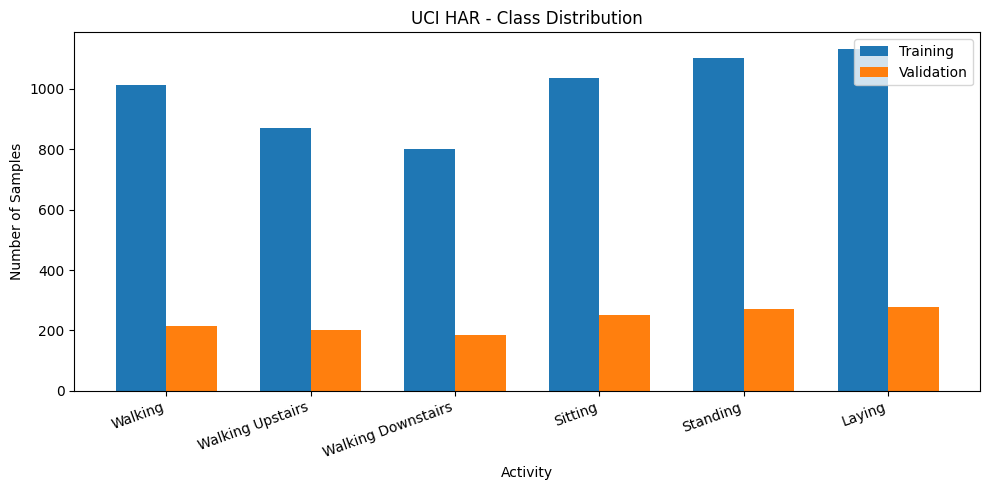

In [18]:

# Section 2.6 - HAR Class Distribution

# Count observations in each activity class
train_counts = np.bincount(har_data["y_train"], minlength=NUM_CLASSES)
val_counts = np.bincount(har_data["y_val"], minlength=NUM_CLASSES)

# Plot training and validation distributions
x = np.arange(NUM_CLASSES)
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, train_counts, width, label="Training")
plt.bar(x + width/2, val_counts, width, label="Validation")

plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.title("UCI HAR - Class Distribution")

plt.xticks(x, CLASS_NAMES, rotation=20, ha="right")
plt.legend()
plt.tight_layout()

# Save figure for the assignment report
plt.savefig(
    FIGURES_DIR / "har_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

# Module 3 - Section 3.1: Adding Problem Generator

def make_adding(n, T, seed):

    # Initialize random number generator
    rng = np.random.default_rng(seed)

    # Create input data with two channels
    x = np.zeros((n, T, 2), dtype=np.float32)

    # Generate random values in the first channel
    x[:, :, 0] = rng.random((n, T))

    # Select one marker position from each half
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    # Mark the selected positions in the second channel
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    # Calculate the sum of the two marked values
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]

    return x, y.astype(np.float32)


In [21]:

# Section 3.2 - Generate Adding Problem Datasets

# Store datasets for all four sequence lengths
adding_data = {}

for T in SEQUENCE_LENGTHS:

    # Generate training data
    X_train_add, y_train_add = make_adding(
        TRAIN_SAMPLES, T, seed=0
    )

    # Generate validation data
    X_val_add, y_val_add = make_adding(
        VALIDATION_SAMPLES, T, seed=1
    )

    # Generate testing data
    X_test_add, y_test_add = make_adding(
        TEST_SAMPLES, T, seed=2
    )

    # Store all datasets
    adding_data[T] = {
        "X_train": X_train_add,
        "y_train": y_train_add,
        "X_val": X_val_add,
        "y_val": y_val_add,
        "X_test": X_test_add,
        "y_test": y_test_add
    }

    print(f"Sequence length T = {T} generated successfully.")

print("\nAll adding problem datasets generated.")


Sequence length T = 50 generated successfully.
Sequence length T = 100 generated successfully.
Sequence length T = 200 generated successfully.
Sequence length T = 400 generated successfully.

All adding problem datasets generated.


In [22]:

# Section 3.3 - Validate Adding Problem Dataset

def validate_adding_data(x, y):

    # Separate random-value and marker channels
    values = x[:, :, 0]
    markers = x[:, :, 1]

    # Confirm exactly two markers in every sequence
    assert np.all(markers.sum(axis=1) == 2)

    # Confirm one marker in each half
    assert np.all(markers[:, :x.shape[1]//2].sum(axis=1) == 1)
    assert np.all(markers[:, x.shape[1]//2:].sum(axis=1) == 1)

    # Recalculate target from the marked values
    calculated_target = (values * markers).sum(axis=1)

    # Compare calculated targets with actual targets
    np.testing.assert_allclose(
        calculated_target, y, atol=1e-6
    )

    return True


# Validate training, validation and test datasets
for T, data in adding_data.items():

    validate_adding_data(data["X_train"], data["y_train"])
    validate_adding_data(data["X_val"], data["y_val"])
    validate_adding_data(data["X_test"], data["y_test"])

    print(f"T = {T}: All dataset validation tests passed.")


T = 50: All dataset validation tests passed.
T = 100: All dataset validation tests passed.
T = 200: All dataset validation tests passed.
T = 400: All dataset validation tests passed.


In [23]:

# Section 4.1 - Vanilla RNN Configuration

# Define RNN dimensions as specified in the assignment
input_size = 9
hidden_size = 64
batch_size = 32

# Calculate the mathematical parameter count
input_weights = input_size * hidden_size
recurrent_weights = hidden_size * hidden_size
bias_parameters = hidden_size

total_parameters = (
    input_weights +
    recurrent_weights +
    bias_parameters
)

# Calculate PyTorch parameter count (two bias vectors)
pytorch_parameters = total_parameters + hidden_size

print("VANILLA RNN CONFIGURATION")
print("-" * 40)

print("Input Size             :", input_size)
print("Hidden Size            :", hidden_size)
print("Batch Size             :", batch_size)

print("\nPARAMETER CALCULATION")
print("-" * 40)

print("Input Weights          :", input_weights)
print("Recurrent Weights      :", recurrent_weights)
print("Mathematical Parameters:", total_parameters)
print("PyTorch Parameters     :", pytorch_parameters)


VANILLA RNN CONFIGURATION
----------------------------------------
Input Size             : 9
Hidden Size            : 64
Batch Size             : 32

PARAMETER CALCULATION
----------------------------------------
Input Weights          : 576
Recurrent Weights      : 4096
Mathematical Parameters: 4736
PyTorch Parameters     : 4800


In [24]:

# Section 4.1(b) - RNN Tensor Dimensions

# Create sample input and previous hidden state
x_t = torch.randn(batch_size, input_size)
h_previous = torch.randn(batch_size, hidden_size)

# Display tensor dimensions
print("Current Input Shape       :", x_t.shape)
print("Previous Hidden State     :", h_previous.shape)

print("Input Weight Shape        :", (hidden_size, input_size))
print("Recurrent Weight Shape    :", (hidden_size, hidden_size))

print("New Hidden State Shape    :", (batch_size, hidden_size))


Current Input Shape       : torch.Size([32, 9])
Previous Hidden State     : torch.Size([32, 64])
Input Weight Shape        : (64, 9)
Recurrent Weight Shape    : (64, 64)
New Hidden State Shape    : (32, 64)


In [25]:

# Section 4.2(b) - Create PyTorch Reference RNN

# Initialize the built-in RNN reference model
reference_rnn = nn.RNN(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=1,
    nonlinearity="tanh",
    bias=True,
    batch_first=True
).to(device)

# Create sample sequential input and initial hidden state
x_test = torch.randn(
    batch_size, 10, input_size, device=device
)

h0 = torch.randn(
    1, batch_size, hidden_size, device=device
)

# Generate reference output
with torch.no_grad():
    reference_output, reference_hidden = reference_rnn(x_test, h0)

print("Reference output shape:", reference_output.shape)
print("Reference hidden shape:", reference_hidden.shape)


Reference output shape: torch.Size([32, 10, 64])
Reference hidden shape: torch.Size([1, 32, 64])


In [28]:
# Section 4.2(c) - Implement MyRNNCell
import math

class MyRNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super(MyRNNCell, self).__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Define the four learnable parameters:
        # 1. Input-to-hidden weights: (hidden_size, input_size)
        self.weight_ih = nn.Parameter(torch.Tensor(hidden_size, input_size))
        # 2. Hidden-to-hidden weights: (hidden_size, hidden_size)
        self.weight_hh = nn.Parameter(torch.Tensor(hidden_size, hidden_size))
        # 3. Input bias: (hidden_size,)
        self.bias_ih = nn.Parameter(torch.Tensor(hidden_size))
        # 4. Hidden bias: (hidden_size,)
        self.bias_hh = nn.Parameter(torch.Tensor(hidden_size))

        # Initialize the weights matching PyTorch's defaults
        self.init_weights()

    def init_weights(self):
        stdv = 1.0 / math.sqrt(self.hidden_size) if self.hidden_size > 0 else 0
        for weight in self.parameters():
            nn.init.uniform_(weight, -stdv, stdv)

    def forward(self, x, h_previous):
        # x shape: (batch_size, input_size)
        # h_previous shape: (batch_size, hidden_size)

        # Implement the vanilla RNN equation:
        # h_t = tanh(x_t * W_ih^T + b_ih + h_{t-1} * W_hh^T + b_hh)
        # Using linear projections:
        h_t = torch.tanh(
            torch.matmul(x, self.weight_ih.t()) + self.bias_ih +
            torch.matmul(h_previous, self.weight_hh.t()) + self.bias_hh
        )
        return h_t

In [29]:

# Section 4.2(d) - RNN Equivalence Testing

# Initialize the custom RNN cell
my_rnn_cell = MyRNNCell(input_size, hidden_size).to(device)

# Copy weights from the PyTorch reference model
with torch.no_grad():
    my_rnn_cell.weight_ih.copy_(reference_rnn.weight_ih_l0)
    my_rnn_cell.weight_hh.copy_(reference_rnn.weight_hh_l0)
    my_rnn_cell.bias_ih.copy_(reference_rnn.bias_ih_l0)
    my_rnn_cell.bias_hh.copy_(reference_rnn.bias_hh_l0)

# Process the input sequence one time step at a time
custom_hidden = h0.squeeze(0)
custom_outputs = []

with torch.no_grad():
    for t in range(x_test.size(1)):
        custom_hidden = my_rnn_cell(x_test[:, t, :], custom_hidden)
        custom_outputs.append(custom_hidden)

# Combine outputs from all time steps
custom_output = torch.stack(custom_outputs, dim=1)

# Compare custom and reference outputs
max_difference = torch.max(
    torch.abs(custom_output - reference_output)
).item()

print("Maximum absolute difference:", max_difference)
print("Required tolerance: 1e-5")

assert max_difference < 1e-5, "RNN equivalence test failed!"

print("RNN equivalence test passed.")


Maximum absolute difference: 7.271766662597656e-06
Required tolerance: 1e-5
RNN equivalence test passed.


In [30]:

# Section 4.2(e) - RNN Parameter Count

# Calculate parameters in the custom RNN
custom_parameters = sum(
    parameter.numel()
    for parameter in my_rnn_cell.parameters()
)

# Calculate parameters in the PyTorch reference RNN
reference_parameters = sum(
    parameter.numel()
    for parameter in reference_rnn.parameters()
)

# Mathematical parameter count
mathematical_parameters = (
    input_size * hidden_size
    + hidden_size * hidden_size
    + hidden_size
)

print("RNN PARAMETER VERIFICATION")
print("-" * 40)

print("Mathematical Parameters :", mathematical_parameters)
print("Custom RNN Parameters   :", custom_parameters)
print("PyTorch Parameters      :", reference_parameters)
print("Additional Bias Parameters:", hidden_size)

assert custom_parameters == 4800
assert reference_parameters == 4800

print("\nParameter count verification passed.")


RNN PARAMETER VERIFICATION
----------------------------------------
Mathematical Parameters : 4736
Custom RNN Parameters   : 4800
PyTorch Parameters      : 4800
Additional Bias Parameters: 64

Parameter count verification passed.


In [31]:

# Section 4.3(a) - Create PyTorch Reference LSTM

reference_lstm = nn.LSTM(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=1,
    bias=True,
    batch_first=True
).to(device)

# Create initial hidden and cell states
h0_lstm = torch.randn(
    1, batch_size, hidden_size, device=device
)

c0_lstm = torch.randn(
    1, batch_size, hidden_size, device=device
)

# Generate reference output
with torch.no_grad():
    lstm_output, (lstm_hidden, lstm_cell) = reference_lstm(
        x_test, (h0_lstm, c0_lstm)
    )

print("LSTM Output Shape:", lstm_output.shape)
print("LSTM Hidden Shape:", lstm_hidden.shape)
print("LSTM Cell Shape:", lstm_cell.shape)


LSTM Output Shape: torch.Size([32, 10, 64])
LSTM Hidden Shape: torch.Size([1, 32, 64])
LSTM Cell Shape: torch.Size([1, 32, 64])


In [32]:

# Section 4.3(b) - LSTM Parameter Count

lstm_math_params = (
    4 * hidden_size * input_size
    + 4 * hidden_size * hidden_size
    + 4 * hidden_size
)

lstm_pytorch_params = sum(
    parameter.numel()
    for parameter in reference_lstm.parameters()
)

print("Mathematical Parameters:", lstm_math_params)
print("PyTorch Parameters:", lstm_pytorch_params)


Mathematical Parameters: 18944
PyTorch Parameters: 19200


In [33]:

# Section 4.5(a) - Create PyTorch Reference GRU

reference_gru = nn.GRU(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=1,
    bias=True,
    batch_first=True
).to(device)

# Create initial hidden state
h0_gru = torch.randn(
    1, batch_size, hidden_size, device=device
)

# Generate reference GRU output
with torch.no_grad():
    gru_output, gru_hidden = reference_gru(x_test, h0_gru)

print("GRU Output Shape:", gru_output.shape)
print("GRU Hidden Shape:", gru_hidden.shape)


GRU Output Shape: torch.Size([32, 10, 64])
GRU Hidden Shape: torch.Size([1, 32, 64])


In [34]:

# Section 4.5(b) - GRU Parameter Count

gru_math_params = (
    3 * hidden_size * input_size
    + 3 * hidden_size * hidden_size
    + 3 * hidden_size
)

gru_pytorch_params = sum(
    parameter.numel()
    for parameter in reference_gru.parameters()
)

print("Mathematical Parameters:", gru_math_params)
print("PyTorch Parameters:", gru_pytorch_params)


Mathematical Parameters: 14208
PyTorch Parameters: 14400


In [35]:

# Section 4.6 - Recurrent Model Parameter Comparison

# Calculate mathematical parameter counts
rnn_math = hidden_size * input_size + hidden_size**2 + hidden_size

lstm_math = (
    4 * hidden_size * input_size
    + 4 * hidden_size**2
    + 4 * hidden_size
)

gru_math = (
    3 * hidden_size * input_size
    + 3 * hidden_size**2
    + 3 * hidden_size
)

# Calculate PyTorch parameter counts
rnn_torch = sum(p.numel() for p in reference_rnn.parameters())
lstm_torch = sum(p.numel() for p in reference_lstm.parameters())
gru_torch = sum(p.numel() for p in reference_gru.parameters())

# Create comparison table
parameter_table = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Mathematical Parameters": [rnn_math, lstm_math, gru_math],
    "PyTorch Parameters": [rnn_torch, lstm_torch, gru_torch]
})

parameter_table["Bias Difference"] = (
    parameter_table["PyTorch Parameters"]
    - parameter_table["Mathematical Parameters"]
)

display(parameter_table)


,Model,Mathematical Parameters,PyTorch Parameters,Bias Difference
0,RNN,4736,4800,64
1,LSTM,18944,19200,256
2,GRU,14208,14400,192


In [36]:

# Section 4.7(a) - RNN Equivalence Testing

# Initialize custom RNN cell
my_rnn_cell = MyRNNCell(input_size, hidden_size).to(device)

# Copy parameters from PyTorch reference model
with torch.no_grad():
    my_rnn_cell.weight_ih.copy_(reference_rnn.weight_ih_l0)
    my_rnn_cell.weight_hh.copy_(reference_rnn.weight_hh_l0)
    my_rnn_cell.bias_ih.copy_(reference_rnn.bias_ih_l0)
    my_rnn_cell.bias_hh.copy_(reference_rnn.bias_hh_l0)

# Generate reference output
with torch.no_grad():
    reference_output, reference_hidden = reference_rnn(x_test, h0)

# Calculate custom RNN outputs one time step at a time
custom_hidden = h0.squeeze(0)
custom_outputs = []

with torch.no_grad():
    for t in range(x_test.size(1)):
        custom_hidden = my_rnn_cell(x_test[:, t, :], custom_hidden)
        custom_outputs.append(custom_hidden)

custom_output = torch.stack(custom_outputs, dim=1)

# Calculate maximum absolute difference
rnn_difference = (reference_output - custom_output).abs().max().item()

print("RNN Maximum Difference:", rnn_difference)
print("RNN Test:", "PASSED" if rnn_difference < 1e-5 else "FAILED")

assert rnn_difference < 1e-5


RNN Maximum Difference: 7.271766662597656e-06
RNN Test: PASSED


In [38]:

# Section 4.7(b) - LSTM Equivalence Testing
import math

class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(MyLSTMCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size

        # PyTorch combines all 4 gates (i, f, g, o) into single parameter tensors
        self.weight_ih = nn.Parameter(torch.Tensor(4 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.Tensor(4 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.Tensor(4 * hidden_size))
        self.bias_hh = nn.Parameter(torch.Tensor(4 * hidden_size))

        self.init_weights()

    def init_weights(self):
        stdv = 1.0 / math.sqrt(self.hidden_size) if self.hidden_size > 0 else 0
        for weight in self.parameters():
            nn.init.uniform_(weight, -stdv, stdv)

    def forward(self, x, h_previous, c_previous):
        # Linear projections for all 4 gates
        gates_ih = torch.matmul(x, self.weight_ih.t()) + self.bias_ih
        gates_hh = torch.matmul(h_previous, self.weight_hh.t()) + self.bias_hh

        gates = gates_ih + gates_hh

        # Split into input, forget, cell gate, output gates
        i, f, g, o = gates.chunk(4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c_t = f * c_previous + i * g
        h_t = o * torch.tanh(c_t)

        return h_t, c_t

# Initialize custom LSTM cell
my_lstm_cell = MyLSTMCell(input_size, hidden_size).to(device)

# Copy parameters from PyTorch reference model
with torch.no_grad():
    my_lstm_cell.weight_ih.copy_(reference_lstm.weight_ih_l0)
    my_lstm_cell.weight_hh.copy_(reference_lstm.weight_hh_l0)
    my_lstm_cell.bias_ih.copy_(reference_lstm.bias_ih_l0)
    my_lstm_cell.bias_hh.copy_(reference_lstm.bias_hh_l0)

# Generate reference output
with torch.no_grad():
    ref_output, (ref_hidden, ref_cell) = reference_lstm(
        x_test, (h0_lstm, c0_lstm)
    )

# Process the sequence using custom LSTM
custom_hidden = h0_lstm.squeeze(0)
custom_cell = c0_lstm.squeeze(0)
custom_outputs = []

with torch.no_grad():
    for t in range(x_test.size(1)):
        custom_hidden, custom_cell = my_lstm_cell(
            x_test[:, t, :], custom_hidden, custom_cell
        )
        custom_outputs.append(custom_hidden)

custom_output = torch.stack(custom_outputs, dim=1)

# Compare hidden sequence and final cell state
lstm_output_difference = (ref_output - custom_output).abs().max().item()

lstm_cell_difference = (
    ref_cell.squeeze(0) - custom_cell
).abs().max().item()

print("LSTM Output Difference:", lstm_output_difference)
print("LSTM Cell Difference  :", lstm_cell_difference)

assert lstm_output_difference < 1e-5
assert lstm_cell_difference < 1e-5

print("LSTM Equivalence Test: PASSED")


LSTM Output Difference: 6.377696990966797e-06
LSTM Cell Difference  : 3.248453140258789e-06
LSTM Equivalence Test: PASSED


In [40]:
# Section 4.7(c) - GRU Equivalence Testing
import math

class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(MyGRUCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size

        # PyTorch groups weights/biases into (3 * hidden_size) tensors for r, z, n gates
        self.weight_ih = nn.Parameter(torch.Tensor(3 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.Tensor(3 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.Tensor(3 * hidden_size))
        self.bias_hh = nn.Parameter(torch.Tensor(3 * hidden_size))

        self.init_weights()

    def init_weights(self):
        stdv = 1.0 / math.sqrt(self.hidden_size) if self.hidden_size > 0 else 0
        for weight in self.parameters():
            nn.init.uniform_(weight, -stdv, stdv)

    def forward(self, x, h_previous):
        # Compute reset, update, and candidate projections
        gates_ih = torch.matmul(x, self.weight_ih.t()) + self.bias_ih
        gates_hh = torch.matmul(h_previous, self.weight_hh.t()) + self.bias_hh

        # Split into reset gate (r), update gate (z), and candidate (n)
        r_ih, z_ih, n_ih = gates_ih.chunk(3, dim=1)
        r_hh, z_hh, n_hh = gates_hh.chunk(3, dim=1)

        r = torch.sigmoid(r_ih + r_hh)
        z = torch.sigmoid(z_ih + z_hh)
        n = torch.tanh(n_ih + r * n_hh)

        h_t = (1 - z) * n + z * h_previous
        return h_t

# Initialize custom GRU cell
my_gru_cell = MyGRUCell(input_size, hidden_size).to(device)

# Copy parameters from PyTorch reference model
with torch.no_grad():
    my_gru_cell.weight_ih.copy_(reference_gru.weight_ih_l0)
    my_gru_cell.weight_hh.copy_(reference_gru.weight_hh_l0)
    my_gru_cell.bias_ih.copy_(reference_gru.bias_ih_l0)
    my_gru_cell.bias_hh.copy_(reference_gru.bias_hh_l0)

# Generate reference output
with torch.no_grad():
    ref_output, ref_hidden = reference_gru(x_test, h0_gru)

# Process sequence using custom GRU
custom_hidden = h0_gru.squeeze(0)
custom_outputs = []

with torch.no_grad():
    for t in range(x_test.size(1)):
        custom_hidden = my_gru_cell(x_test[:, t, :], custom_hidden)
        custom_outputs.append(custom_hidden)

custom_output = torch.stack(custom_outputs, dim=1)

# Calculate output and hidden-state differences
gru_output_difference = (ref_output - custom_output).abs().max().item()

gru_hidden_difference = (
    ref_hidden.squeeze(0) - custom_hidden
).abs().max().item()

print("GRU Output Difference :", gru_output_difference)
print("GRU Hidden Difference :", gru_hidden_difference)

assert gru_output_difference < 1e-5
assert gru_hidden_difference < 1e-5

print("GRU Equivalence Test: PASSED")

GRU Output Difference : 4.947185516357422e-06
GRU Hidden Difference : 2.950429916381836e-06
GRU Equivalence Test: PASSED


In [41]:

# Section 4.7(d) - Consolidated Equivalence Results

verification_results = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Maximum Difference": [
        rnn_difference,
        max(lstm_output_difference, lstm_cell_difference),
        max(gru_output_difference, gru_hidden_difference)
    ]
})

verification_results["Tolerance"] = 1e-5

verification_results["Result"] = np.where(
    verification_results["Maximum Difference"] < 1e-5,
    "PASSED",
    "FAILED"
)

display(verification_results)


,Model,Maximum Difference,Tolerance,Result
0,RNN,0.000007,0.00001,PASSED
1,LSTM,0.000006,0.00001,PASSED
2,GRU,0.000005,0.00001,PASSED


In [42]:

# Section 5.1 - Define RNN, LSTM and GRU Classifiers

class HARClassifier(nn.Module):

    def __init__(self, model_type, input_size, hidden_size, num_classes):

        super(HARClassifier, self).__init__()

        self.model_type = model_type.upper()

        # Select the recurrent architecture
        if self.model_type == "RNN":
            self.recurrent = nn.RNN(
                input_size, hidden_size,
                batch_first=True
            )

        elif self.model_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size, hidden_size,
                batch_first=True
            )

        elif self.model_type == "GRU":
            self.recurrent = nn.GRU(
                input_size, hidden_size,
                batch_first=True
            )

        # Fully connected classification layer
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x):

        # Process the complete sensor sequence
        output, hidden = self.recurrent(x)

        # Extract the final hidden state
        if self.model_type == "LSTM":
            hidden = hidden[0]

        final_hidden = hidden[-1]

        # Predict one of the six activities
        return self.classifier(final_hidden)


In [43]:

# Section 5.2 - Initialize HAR Classification Models

# Define the three recurrent architectures
model_names = ["RNN", "LSTM", "GRU"]

# Initialize each model
models = {}

for name in model_names:

    models[name] = HARClassifier(
        model_type=name,
        input_size=INPUT_SIZE,
        hidden_size=HIDDEN_SIZE,
        num_classes=NUM_CLASSES
    ).to(device)

    print(f"{name} model initialized successfully.")


RNN model initialized successfully.
LSTM model initialized successfully.
GRU model initialized successfully.


In [44]:

# Section 5.2(b) - Verify Model Architectures

# Obtain one batch of HAR training data
sample_input, sample_labels = next(iter(train_loader))

# Move input data to the selected device
sample_input = sample_input.to(device)

# Check each model's output dimensions and parameters
for name, model in models.items():

    with torch.no_grad():
        predictions = model(sample_input)

    # Calculate total trainable parameters
    parameters = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    print(f"\n{name} Classifier")
    print("Input Shape :", sample_input.shape)
    print("Output Shape:", predictions.shape)
    print("Parameters  :", parameters)



RNN Classifier
Input Shape : torch.Size([128, 128, 9])
Output Shape: torch.Size([128, 6])
Parameters  : 5190

LSTM Classifier
Input Shape : torch.Size([128, 128, 9])
Output Shape: torch.Size([128, 6])
Parameters  : 19590

GRU Classifier
Input Shape : torch.Size([128, 128, 9])
Output Shape: torch.Size([128, 6])
Parameters  : 14790


In [45]:

# Section 5.3(a) - Model Training Function

def train_one_epoch(model, loader, criterion, optimizer):

    # Set model to training mode
    model.train()

    total_loss = 0
    start_time = time.perf_counter()

    for features, labels in loader:

        # Move data to GPU or CPU
        features = features.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(features)
        loss = criterion(outputs, labels)

        # Backpropagation and weight update
        loss.backward()
        optimizer.step()

        # Accumulate batch loss
        total_loss += loss.item() * labels.size(0)

    # Calculate average epoch loss and training time
    epoch_loss = total_loss / len(loader.dataset)
    epoch_time = time.perf_counter() - start_time

    return epoch_loss, epoch_time


In [46]:

# Section 5.3(b) - Model Evaluation Function

def evaluate_model(model, loader, criterion):

    # Set model to evaluation mode
    model.eval()

    total_loss = 0
    predictions = []
    actual_labels = []

    # Disable gradient calculation during evaluation
    with torch.no_grad():

        for features, labels in loader:

            # Move data to the selected device
            features = features.to(device)
            labels = labels.to(device)

            # Generate predictions
            outputs = model(features)
            loss = criterion(outputs, labels)

            # Calculate predicted classes
            predicted = outputs.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)

            predictions.extend(predicted.cpu().numpy())
            actual_labels.extend(labels.cpu().numpy())

    # Calculate evaluation metrics
    average_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(actual_labels, predictions)

    macro_f1 = f1_score(
        actual_labels,
        predictions,
        average="macro"
    )

    return average_loss, accuracy, macro_f1


In [47]:

# Section 5.4(a) - Train RNN, LSTM and GRU

import copy

# Store the best model across all experiments
best_har_val_f1 = -1.0
best_har_model_name = None
best_har_seed = None
best_har_state = None

# Store results of individual training runs
har_experiment_results = []

# Train each architecture using three random seeds
for model_name in ["RNN", "LSTM", "GRU"]:

    for seed in SEEDS:

        print(f"\nTraining {model_name} | Seed: {seed}")

        # Set random seed for reproducibility
        set_seed(seed)

        # Prepare data for the selected seed
        train_loader, val_loader, test_loader, har_data = create_har_loaders(seed)

        # Initialize a fresh model
        model = HARClassifier(
            model_type=model_name,
            input_size=INPUT_SIZE,
            hidden_size=HIDDEN_SIZE,
            num_classes=NUM_CLASSES
        ).to(device)

        # Define optimizer and loss function
        optimizer = optim.Adam(
            model.parameters(),
            lr=LEARNING_RATE
        )

        criterion = nn.CrossEntropyLoss()

        # Track the best validation performance
        run_best_val_f1 = -1.0
        best_state = None
        best_epoch = 0
        epoch_times = []

        # Execute training epochs
        for epoch in range(EPOCHS):

            # Train for one epoch
            train_loss, epoch_time = train_one_epoch(
                model, train_loader, criterion, optimizer
            )

            epoch_times.append(epoch_time)

            # Evaluate on validation data
            val_loss, val_acc, val_f1 = evaluate_model(
                model, val_loader, criterion
            )

            # Save the best validation checkpoint
            if val_f1 > run_best_val_f1:

                run_best_val_f1 = val_f1
                best_epoch = epoch + 1
                best_state = copy.deepcopy(model.state_dict())

            if (epoch + 1) % 5 == 0:
                print(
                    f"Epoch {epoch+1}/{EPOCHS} | "
                    f"Train Loss: {train_loss:.4f} | "
                    f"Val Acc: {val_acc:.4f} | "
                    f"Val Macro-F1: {val_f1:.4f}"
                )

        # Restore the best validation checkpoint
        model.load_state_dict(best_state)

        # Evaluate the selected model on test data
        test_loss, test_acc, test_f1 = evaluate_model(
            model, test_loader, criterion
        )

        # Calculate trainable parameters and average epoch time
        parameters = sum(
            p.numel() for p in model.parameters() if p.requires_grad
        )

        avg_epoch_time = np.mean(epoch_times)

        # Prepare experiment result
        result = {
            "problem": "P1_HAR",
            "model": model_name,
            "seed": seed,
            "seq_len": SEQUENCE_LENGTH,
            "test_acc": test_acc,
            "macro_f1": test_f1,
            "test_mse": np.nan,
            "params": parameters,
            "sec_per_epoch": avg_epoch_time,
            "val_loss_nats": np.nan,
            "bits_per_char": np.nan,
            "notes": (
                f"Best epoch={best_epoch}; "
                f"validation macro-F1={run_best_val_f1:.4f}"
            )
        }

        har_experiment_results.append(result)

        # Save results immediately after each completed run
        existing_results = pd.read_csv(RESULTS_FILE)

        # Replace an earlier record if this experiment is rerun
        if not existing_results.empty:
            keep = ~(
                (existing_results["problem"] == "P1_HAR") &
                (existing_results["model"] == model_name) &
                (existing_results["seed"] == seed)
            )
            existing_results = existing_results[keep]

        updated_results = pd.concat(
            [existing_results, pd.DataFrame([result])],
            ignore_index=True
        )

        updated_results.to_csv(RESULTS_FILE, index=False)

        # Retain the best model based on validation macro-F1
        if run_best_val_f1 > best_har_val_f1:

            best_har_val_f1 = run_best_val_f1
            best_har_model_name = model_name
            best_har_seed = seed

            best_har_state = {
                key: value.detach().cpu().clone()
                for key, value in best_state.items()
            }

        print(
            f"Completed {model_name} | Seed {seed} | "
            f"Test Accuracy: {test_acc:.4f} | "
            f"Test Macro-F1: {test_f1:.4f}"
        )

        print("Results saved to results.csv")

print("\nAll nine HAR experiments completed.")



Training RNN | Seed: 42
Epoch 5/20 | Train Loss: 1.1343 | Val Acc: 0.5736 | Val Macro-F1: 0.4863
Epoch 10/20 | Train Loss: 0.9971 | Val Acc: 0.4757 | Val Macro-F1: 0.3959
Epoch 15/20 | Train Loss: 0.8661 | Val Acc: 0.5657 | Val Macro-F1: 0.5080
Epoch 20/20 | Train Loss: 0.7154 | Val Acc: 0.6393 | Val Macro-F1: 0.5959
Completed RNN | Seed 42 | Test Accuracy: 0.6274 | Test Macro-F1: 0.6021
Results saved to results.csv

Training RNN | Seed: 123


/tmp/ipykernel_4815/2794923401.py:127: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated_results = pd.concat(


Epoch 5/20 | Train Loss: 1.0519 | Val Acc: 0.4856 | Val Macro-F1: 0.4149
Epoch 10/20 | Train Loss: 0.9899 | Val Acc: 0.5804 | Val Macro-F1: 0.5154
Epoch 15/20 | Train Loss: 0.7444 | Val Acc: 0.5865 | Val Macro-F1: 0.5303
Epoch 20/20 | Train Loss: 1.3994 | Val Acc: 0.4663 | Val Macro-F1: 0.3802
Completed RNN | Seed 123 | Test Accuracy: 0.6026 | Test Macro-F1: 0.5650
Results saved to results.csv

Training RNN | Seed: 2026
Epoch 5/20 | Train Loss: 1.0651 | Val Acc: 0.5178 | Val Macro-F1: 0.4199
Epoch 10/20 | Train Loss: 1.2799 | Val Acc: 0.5806 | Val Macro-F1: 0.5181
Epoch 15/20 | Train Loss: 0.7737 | Val Acc: 0.6220 | Val Macro-F1: 0.5856
Epoch 20/20 | Train Loss: 0.5962 | Val Acc: 0.7161 | Val Macro-F1: 0.6851
Completed RNN | Seed 2026 | Test Accuracy: 0.7000 | Test Macro-F1: 0.6805
Results saved to results.csv

Training LSTM | Seed: 42
Epoch 5/20 | Train Loss: 1.2079 | Val Acc: 0.4771 | Val Macro-F1: 0.4014
Epoch 10/20 | Train Loss: 0.8015 | Val Acc: 0.6293 | Val Macro-F1: 0.5638
Epoch

In [48]:

# Section 5.4(b) - HAR Experimental Results

har_results_df = pd.DataFrame(har_experiment_results)

display(
    har_results_df[
        [
            "model",
            "seed",
            "test_acc",
            "macro_f1",
            "params",
            "sec_per_epoch"
        ]
    ].round(4)
)

print("\nBest model:", best_har_model_name)
print("Best seed:", best_har_seed)
print("Best validation Macro-F1:", round(best_har_val_f1, 4))


,model,seed,test_acc,macro_f1,params,sec_per_epoch
0,RNN,42,0.6274,0.6021,5190,0.1570
1,RNN,123,0.6026,0.5650,5190,0.1479
2,RNN,2026,0.7000,0.6805,5190,0.1685
3,LSTM,42,0.7408,0.7343,19590,0.1595
4,LSTM,123,0.6101,0.5577,19590,0.1577
5,LSTM,2026,0.6841,0.6757,19590,0.1913
6,GRU,42,0.8605,0.8632,14790,0.1550
7,GRU,123,0.8731,0.8723,14790,0.1543
8,GRU,2026,0.8653,0.8651,14790,0.1768



Best model: GRU
Best seed: 2026
Best validation Macro-F1: 0.925


In [49]:

# Section 5.5 - HAR Performance Summary

# Calculate mean and sample standard deviation for each model
har_summary = har_results_df.groupby("model").agg(
    accuracy_mean=("test_acc", "mean"),
    accuracy_std=("test_acc", "std"),
    f1_mean=("macro_f1", "mean"),
    f1_std=("macro_f1", "std"),
    parameters=("params", "first"),
    epoch_time_mean=("sec_per_epoch", "mean"),
    epoch_time_std=("sec_per_epoch", "std")
).reset_index()

# Format performance metrics as mean ± standard deviation
har_summary["Test Accuracy"] = har_summary.apply(
    lambda r: f"{r['accuracy_mean']*100:.2f} ± {r['accuracy_std']*100:.2f}%",
    axis=1
)

har_summary["Macro-F1"] = har_summary.apply(
    lambda r: f"{r['f1_mean']:.4f} ± {r['f1_std']:.4f}",
    axis=1
)

har_summary["Epoch Time (sec)"] = har_summary.apply(
    lambda r: f"{r['epoch_time_mean']:.4f} ± {r['epoch_time_std']:.4f}",
    axis=1
)

# Display final comparison
display(
    har_summary[
        ["model", "Test Accuracy", "Macro-F1", "parameters", "Epoch Time (sec)"]
    ]
)


,model,Test Accuracy,Macro-F1,parameters,Epoch Time (sec)
0,GRU,86.63 ± 0.63%,0.8669 ± 0.0048,14790,0.1620 ± 0.0128
1,LSTM,67.83 ± 6.55%,0.6559 ± 0.0900,19590,0.1695 ± 0.0189
2,RNN,64.34 ± 5.06%,0.6159 ± 0.0589,5190,0.1578 ± 0.0103


In [50]:

# Section 5.6(a) - Load Best HAR Model

# Prepare test data using the selected seed's normalization
_, _, best_test_loader, best_har_data = create_har_loaders(best_har_seed)

# Initialize the selected architecture
best_model = HARClassifier(
    model_type=best_har_model_name,
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_classes=NUM_CLASSES
).to(device)

# Load the best validation checkpoint
best_model.load_state_dict(best_har_state)

best_model.eval()

print("Best model loaded:", best_har_model_name)
print("Selected seed:", best_har_seed)


Best model loaded: GRU
Selected seed: 2026


In [51]:

# Section 5.6(b) - Generate Confusion Matrix

# Collect actual and predicted activity labels
actual_labels = []
predicted_labels = []

with torch.no_grad():

    for features, labels in best_test_loader:

        features = features.to(device)

        # Generate model predictions
        outputs = best_model(features)
        predictions = outputs.argmax(dim=1)

        # Store predictions and actual labels
        predicted_labels.extend(predictions.cpu().numpy())
        actual_labels.extend(labels.numpy())

# Calculate confusion matrix
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=np.arange(NUM_CLASSES)
)

# Display classification metrics
print("Test Accuracy:", accuracy_score(actual_labels, predicted_labels))
print(
    "Test Macro-F1:",
    f1_score(actual_labels, predicted_labels, average="macro")
)

print("\nConfusion Matrix:")
print(cm)


Test Accuracy: 0.8652867322701052
Test Macro-F1: 0.8651413336962465

Confusion Matrix:
[[462  18  12   0   4   0]
 [114 357   0   0   0   0]
 [ 47   3 370   0   0   0]
 [  0   2   0 348 141   0]
 [  1   0   0  53 478   0]
 [  0   2   0   0   0 535]]


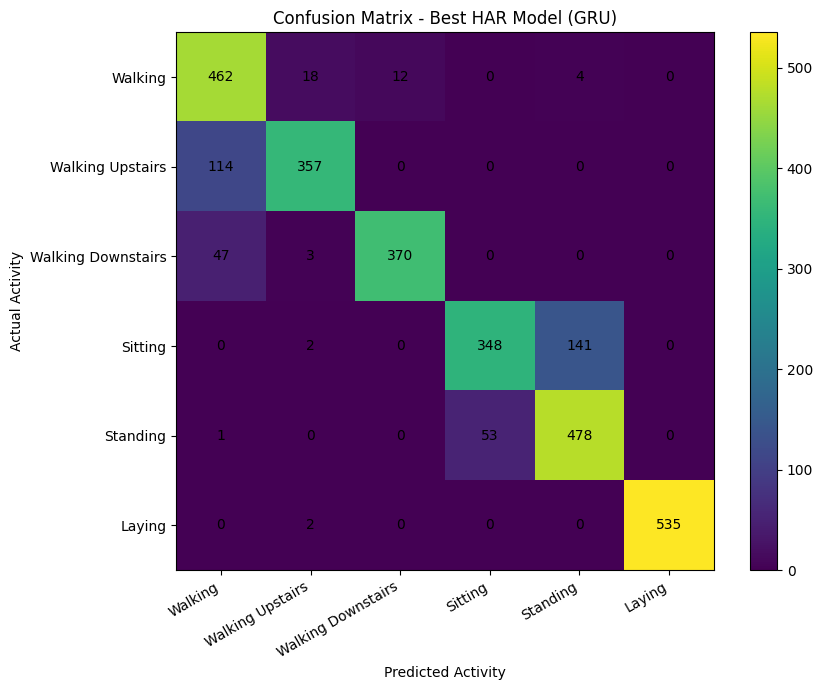

In [52]:

# Section 5.6(c) - Plot Best Model Confusion Matrix

plt.figure(figsize=(9, 7))

plt.imshow(cm, interpolation="nearest")
plt.colorbar()

plt.xticks(
    np.arange(NUM_CLASSES),
    CLASS_NAMES,
    rotation=30,
    ha="right"
)

plt.yticks(np.arange(NUM_CLASSES), CLASS_NAMES)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")

plt.title("Confusion Matrix - Best HAR Model (GRU)")

# Display observation counts inside each cell
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()

# Save figure for the final report
plt.savefig(
    FIGURES_DIR / "har_best_model_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [53]:

# Section 5.7 - Verify HAR Experimental Results

# Load the consolidated results file
all_results = pd.read_csv(RESULTS_FILE)

# Extract Problem 1 HAR experiments
har_final_results = all_results[
    all_results["problem"] == "P1_HAR"
]

print("Total HAR experiments:", len(har_final_results))

display(
    har_final_results[
        ["model", "seed", "test_acc", "macro_f1", "params", "sec_per_epoch"]
    ]
)

print("\nResults saved successfully:", RESULTS_FILE)


Total HAR experiments: 9


,model,seed,test_acc,macro_f1,params,sec_per_epoch
0,RNN,42,0.627418,0.602112,5190,0.157014
1,RNN,123,0.602647,0.565004,5190,0.147900
2,RNN,2026,0.700034,0.680460,5190,0.168489
3,LSTM,42,0.740753,0.734298,19590,0.159520
4,LSTM,123,0.610112,0.557680,19590,0.157674
5,LSTM,2026,0.684086,0.675732,19590,0.191329
6,GRU,42,0.860536,0.863179,14790,0.155048
7,GRU,123,0.873091,0.872335,14790,0.154286
8,GRU,2026,0.865287,0.865141,14790,0.176763



Results saved successfully: /content/results.csv


In [5]:
# ============================================================
# MODULE 7.0(a) — CONFIGURATION
# ============================================================

import copy
import time
import numpy as np
import torch
from torch.utils.data import TensorDataset

# Experiment sequence lengths
T_GRADIENT = 100
T_ABLATION = 200

# Gradient analysis configuration
GRADIENT_BATCH_SIZE = 128

# Hidden-size sweep configuration
HIDDEN_SIZE_SWEEP = [16, 32, 64, 128]

# Individual ablation configuration
CLIP_NORM = 1.0

# Safely retrieve SEEDS or fallback if not yet defined
ABLATION_SEEDS = globals().get("SEEDS", [42, 123, 2026])

# Reuse the existing assignment generator.
# Define it only if the Module 3 cell has not been executed.

if "make_adding" not in globals():

    def make_adding(n, T, seed):

        rng = np.random.default_rng(seed)

        x = np.zeros((n, T, 2), dtype=np.float32)
        x[:, :, 0] = rng.random((n, T))

        i1 = rng.integers(0, T // 2, n)
        i2 = rng.integers(T // 2, T, n)

        x[np.arange(n), i1, 1] = 1
        x[np.arange(n), i2, 1] = 1

        y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]

        return x, y.astype(np.float32)


# Ensure output directories exist
if "FIGURES_DIR" in globals():
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
else:
    from pathlib import Path
    FIGURES_DIR = Path("./problem1/figures")
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Verify the adding-problem generator
X_check, y_check = make_adding(16, T_GRADIENT, seed=42)

assert X_check.shape == (16, 100, 2)
assert y_check.shape == (16,)
assert np.all(X_check[:, :, 1].sum(axis=1) == 2)

print("MODULE 7 CONFIGURATION")
print("-" * 40)
print("Student ID          :", globals().get("STUDENT_ID", "05160"))
print("Gradient sequence   :", T_GRADIENT)
print("Ablation sequence   :", T_ABLATION)
print("Gradient batch size :", GRADIENT_BATCH_SIZE)
print("Hidden sizes        :", HIDDEN_SIZE_SWEEP)
print("Random seeds        :", ABLATION_SEEDS)
print("Clipping norm       :", CLIP_NORM)
print("Individual ablation :", globals().get("INDIVIDUAL_ABLATION", "RNN Gradient Clipping"))

print("\nConfiguration and generator verified successfully.")

MODULE 7 CONFIGURATION
----------------------------------------
Student ID          : 05160
Gradient sequence   : 100
Ablation sequence   : 200
Gradient batch size : 128
Hidden sizes        : [16, 32, 64, 128]
Random seeds        : [42, 123, 2026]
Clipping norm       : 1.0
Individual ablation : RNN Gradient Clipping

Configuration and generator verified successfully.


In [6]:
# ============================================================
# 7.0(a) — Correct HAR preprocessing
# Training-only mean and standard deviation
# ============================================================

def prepare_har_data(seed):

    # Create the subject-wise validation split
    train_mask, val_mask, _ = create_subject_split(seed)

    X_tr = X_train_raw[train_mask].copy()
    y_tr = y_train[train_mask]

    X_val = X_train_raw[val_mask].copy()
    y_val = y_train[val_mask]

    X_test = X_test_raw.copy()

    # Calculate per-channel statistics from training data only
    mean = X_tr.mean(axis=(0, 1), keepdims=True)
    std = X_tr.std(axis=(0, 1), keepdims=True)

    # Avoid division by zero
    std = np.where(std < 1e-8, 1.0, std)

    # Apply the same training statistics to all splits
    X_tr = ((X_tr - mean) / std).astype(np.float32)
    X_val = ((X_val - mean) / std).astype(np.float32)
    X_test = ((X_test - mean) / std).astype(np.float32)

    return {
        "X_train": X_tr,
        "y_train": y_tr,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_test,
        "y_test": y_test
    }


print("HAR preprocessing updated with training-only normalization.")

HAR preprocessing updated with training-only normalization.


In [8]:
# ============================================================
# 7.1(a) — Adding Problem recurrent model
# ============================================================

import torch.nn as nn

class AddingSequenceModel(nn.Module):

    def __init__(self, model_type, input_size=2, hidden_size=64):

        super().__init__()

        self.model_type = model_type.upper()
        self.hidden_size = hidden_size

        if self.model_type == "RNN":

            self.recurrent = nn.RNN(
                input_size,
                hidden_size,
                batch_first=True
            )

        elif self.model_type == "LSTM":

            self.recurrent = nn.LSTM(
                input_size,
                hidden_size,
                batch_first=True
            )

        elif self.model_type == "GRU":

            self.recurrent = nn.GRU(
                input_size,
                hidden_size,
                batch_first=True
            )

        self.regressor = nn.Linear(hidden_size, 1)

    def forward(self, x):

        if self.model_type == "LSTM":

            _, (hidden, cell) = self.recurrent(x)

        else:

            _, hidden = self.recurrent(x)

        # Use the final hidden state for regression
        final_hidden = hidden[-1]

        return self.regressor(final_hidden).squeeze(-1)

In [9]:
# ============================================================
# 7.1(b) — Generate data and create DataLoaders
# ============================================================

def create_adding_loaders(T, shuffle_seed):

    X_train, y_train = make_adding(
        TRAIN_SAMPLES, T, seed=0
    )

    X_val, y_val = make_adding(
        VALIDATION_SAMPLES, T, seed=1
    )

    X_test, y_test = make_adding(
        TEST_SAMPLES, T, seed=2
    )

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    )

    val_dataset = TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32)
    )

    test_dataset = TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32)
    )

    generator = torch.Generator()
    generator.manual_seed(shuffle_seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return train_loader, val_loader, test_loader

In [11]:
# ============================================================
# 7.1(c) — Adding Problem training function
# ============================================================

def train_adding_model(
    model,
    train_loader,
    val_loader,
    epochs=None,
    lr=None,
    clip_norm=None
):
    # Safely retrieve parameters or fallback
    if epochs is None:
        epochs = globals().get("EPOCHS", 20)
    if lr is None:
        lr = globals().get("LEARNING_RATE", 0.001)

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    criterion = nn.MSELoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "epoch_time": []
    }

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(epochs):

        start_time = time.perf_counter()

        # Training
        model.train()
        total_train_loss = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            loss.backward()

            # Apply clipping only when requested
            if clip_norm is not None:

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=clip_norm
                )

            optimizer.step()

            total_train_loss += loss.item() * len(y_batch)

        train_loss = total_train_loss / len(train_loader.dataset)

        # Validation
        model.eval()
        total_val_loss = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                predictions = model(X_batch)

                loss = criterion(predictions, y_batch)

                total_val_loss += loss.item() * len(y_batch)

        val_loss = total_val_loss / len(val_loader.dataset)

        epoch_time = time.perf_counter() - start_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_time"].append(epoch_time)

        # Keep the best validation checkpoint
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

        if (epoch + 1) % 5 == 0:

            print(
                f"Epoch {epoch+1}/{epochs} | "
                f"Train MSE: {train_loss:.5f} | "
                f"Val MSE: {val_loss:.5f}"
            )

    model.load_state_dict(best_state)

    return history, best_epoch

In [12]:
# ============================================================
# 7.1(d) — Hidden-state gradient measurement model
# ============================================================

class HiddenStateGradientProbe(nn.Module):

    def __init__(self, model_type, hidden_size=64):

        super().__init__()

        self.model_type = model_type.upper()
        self.hidden_size = hidden_size

        if self.model_type == "RNN":

            self.cell = nn.RNNCell(2, hidden_size)

        elif self.model_type == "LSTM":

            self.cell = nn.LSTMCell(2, hidden_size)

        elif self.model_type == "GRU":

            self.cell = nn.GRUCell(2, hidden_size)

        self.regressor = nn.Linear(hidden_size, 1)

    def forward(self, x, retain_grad=False):

        batch_size = x.size(0)

        h = x.new_zeros(batch_size, self.hidden_size)

        if self.model_type == "LSTM":
            c = x.new_zeros(batch_size, self.hidden_size)

        hidden_states = []

        # Process the sequence one timestep at a time
        for t in range(x.size(1)):

            if self.model_type == "LSTM":

                h, c = self.cell(
                    x[:, t, :],
                    (h, c)
                )

            else:

                h = self.cell(
                    x[:, t, :],
                    h
                )

            # Retain the gradient of this actual hidden state
            if retain_grad:
                h.retain_grad()

            hidden_states.append(h)

        prediction = self.regressor(h).squeeze(-1)

        return prediction, hidden_states


def copy_to_gradient_probe(source_model):

    probe = HiddenStateGradientProbe(
        source_model.model_type,
        source_model.hidden_size
    ).to(device)

    # Copy the trained recurrent weights to the corresponding cell
    with torch.no_grad():

        for name in [
            "weight_ih",
            "weight_hh",
            "bias_ih",
            "bias_hh"
        ]:

            getattr(probe.cell, name).copy_(
                getattr(source_model.recurrent, name + "_l0")
            )

        probe.regressor.load_state_dict(
            source_model.regressor.state_dict()
        )

    return probe


def calculate_hidden_gradient_norms(model, X, y):

    model.zero_grad(set_to_none=True)

    predictions, hidden_states = model(
        X,
        retain_grad=True
    )

    loss = nn.MSELoss()(predictions, y)

    loss.backward()

    # Calculate average gradient norm across the batch at each timestep
    gradient_norms = []

    for h_t in hidden_states:

        gradient_norm = h_t.grad.norm(dim=1).mean().item()

        gradient_norms.append(gradient_norm)

    return np.array(gradient_norms), loss.item()

In [21]:
import matplotlib.pyplot as plt

In [19]:
# ============================================================
# 7.1(e) — Gradient analysis before and after training
# ============================================================

gradient_before = {}
gradient_after = {}
gradient_histories = {}

# Ensure essential imports are present locally
import torch
import torch.optim as optim
from torch.utils.data import DataLoader

# Safely resolve the computing device
device = globals().get("device", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

# Safely resolve SEEDS and hyperparameters
SEEDS = globals().get("SEEDS", [42, 123, 2026])
HIDDEN_SIZE = globals().get("HIDDEN_SIZE", 64)
EPOCHS = globals().get("EPOCHS", 20)
LEARNING_RATE = globals().get("LEARNING_RATE", 0.001)
BATCH_SIZE = globals().get("BATCH_SIZE", 128)

# Safely resolve adding dataset sizes
TRAIN_SAMPLES = globals().get("TRAIN_SAMPLES", 10000)
VALIDATION_SAMPLES = globals().get("VALIDATION_SAMPLES", 1000)
TEST_SAMPLES = globals().get("TEST_SAMPLES", 1000)

# Ensure set_seed is defined
if "set_seed" not in globals():
    import random
    import numpy as np
    def set_seed(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
else:
    set_seed = globals()["set_seed"]

# Fixed batch for a fair before/after comparison
X_grad_np, y_grad_np = make_adding(
    GRADIENT_BATCH_SIZE,
    T_GRADIENT,
    seed=999
)

X_grad = torch.tensor(
    X_grad_np,
    dtype=torch.float32,
    device=device
)

y_grad = torch.tensor(
    y_grad_np,
    dtype=torch.float32,
    device=device
)

for model_name in ["RNN", "LSTM", "GRU"]:

    print(f"\nGradient experiment: {model_name}")

    set_seed(SEEDS[0])

    train_loader, val_loader, test_loader = create_adding_loaders(
        T_GRADIENT,
        shuffle_seed=SEEDS[0]
    )

    model = AddingSequenceModel(
        model_name,
        input_size=2,
        hidden_size=HIDDEN_SIZE
    ).to(device)

    # Measure gradients before training
    probe_before = copy_to_gradient_probe(model)

    gradient_before[model_name], initial_loss = (
        calculate_hidden_gradient_norms(
            probe_before,
            X_grad,
            y_grad
        )
    )

    # Train the recurrent model
    history, best_epoch = train_adding_model(
        model,
        train_loader,
        val_loader,
        epochs=EPOCHS,
        lr=LEARNING_RATE
    )

    gradient_histories[model_name] = history

    # Transfer the trained weights to the gradient probe
    probe_after = copy_to_gradient_probe(model)

    gradient_after[model_name], final_loss = (
        calculate_hidden_gradient_norms(
            probe_after,
            X_grad,
            y_grad
        )
    )

    print("Initial batch MSE:", round(initial_loss, 6))
    print("Final batch MSE  :", round(final_loss, 6))
    print("Best epoch       :", best_epoch)

print("\nAll three gradient experiments completed.")


Gradient experiment: RNN
Epoch 5/20 | Train MSE: 0.16782 | Val MSE: 0.16044
Epoch 10/20 | Train MSE: 0.16801 | Val MSE: 0.16099
Epoch 15/20 | Train MSE: 0.16787 | Val MSE: 0.16202
Epoch 20/20 | Train MSE: 0.16802 | Val MSE: 0.16038
Initial batch MSE: 1.029766
Final batch MSE  : 0.175057
Best epoch       : 2

Gradient experiment: LSTM
Epoch 5/20 | Train MSE: 0.16780 | Val MSE: 0.16145
Epoch 10/20 | Train MSE: 0.16777 | Val MSE: 0.16117
Epoch 15/20 | Train MSE: 0.16761 | Val MSE: 0.16133
Epoch 20/20 | Train MSE: 0.16803 | Val MSE: 0.16028
Initial batch MSE: 1.529787
Final batch MSE  : 0.176492
Best epoch       : 3

Gradient experiment: GRU
Epoch 5/20 | Train MSE: 0.16672 | Val MSE: 0.15963
Epoch 10/20 | Train MSE: 0.16224 | Val MSE: 0.15170
Epoch 15/20 | Train MSE: 0.00820 | Val MSE: 0.00677
Epoch 20/20 | Train MSE: 0.00450 | Val MSE: 0.00362
Initial batch MSE: 1.129541
Final batch MSE  : 0.0038
Best epoch       : 20

All three gradient experiments completed.


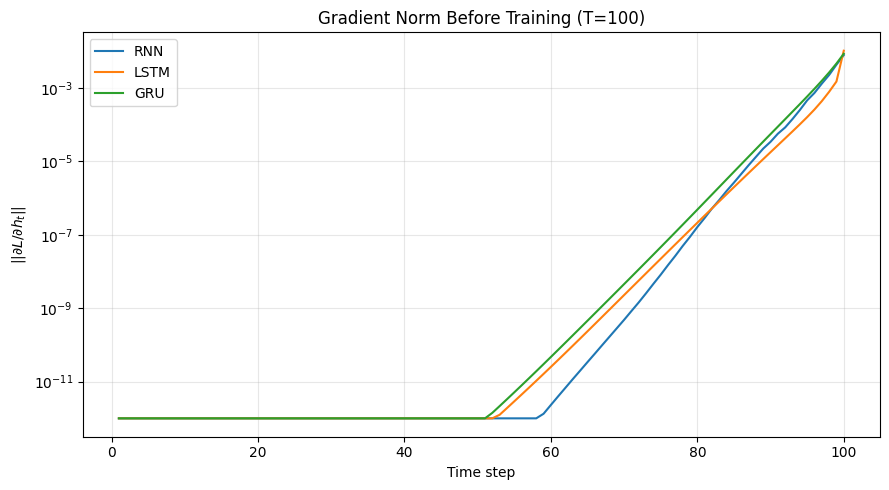

In [22]:
# ============================================================
# 7.1(f) — Gradient Norm Before Training
# ============================================================

plt.figure(figsize=(9, 5))

for model_name in ["RNN", "LSTM", "GRU"]:

    values = np.maximum(
        gradient_before[model_name],
        1e-12
    )

    plt.plot(
        range(1, T_GRADIENT + 1),
        values,
        label=model_name
    )

plt.yscale("log")
plt.xlabel("Time step")
plt.ylabel(r"$||\partial L / \partial h_t||$")
plt.title("Gradient Norm Before Training (T=100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "gradient_norm_before_training.png",
    dpi=300
)

plt.show()

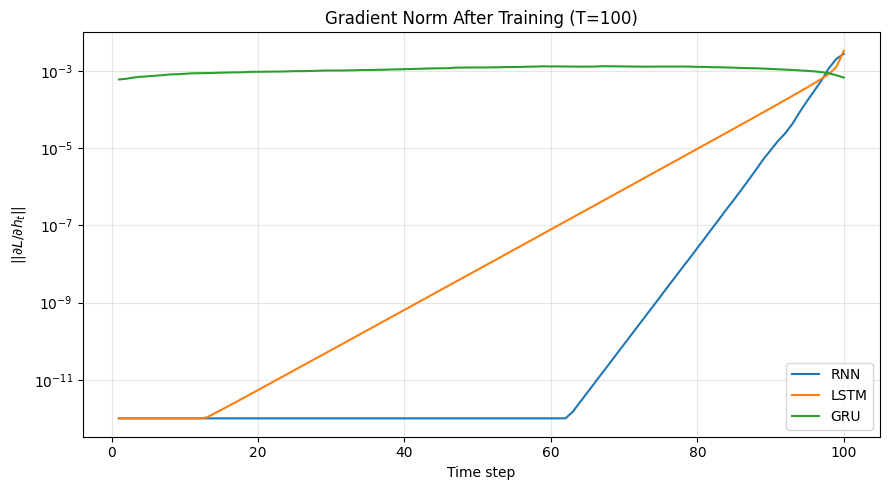

In [23]:
# ============================================================
# 7.1(g) — Gradient Norm After Training
# ============================================================

plt.figure(figsize=(9, 5))

for model_name in ["RNN", "LSTM", "GRU"]:

    values = np.maximum(
        gradient_after[model_name],
        1e-12
    )

    plt.plot(
        range(1, T_GRADIENT + 1),
        values,
        label=model_name
    )

plt.yscale("log")
plt.xlabel("Time step")
plt.ylabel(r"$||\partial L / \partial h_t||$")
plt.title("Gradient Norm After Training (T=100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "gradient_norm_after_training.png",
    dpi=300
)

plt.show()